In [110]:
from pathlib import Path
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import average_precision_score
import matplotlib.pyplot as plt

## Wczytywanie danych

In [111]:
data_path = Path('ml-latest-small')

In [112]:
movies_df = pd.read_csv(data_path / 'movies.csv')
tags_df = pd.read_csv(data_path / 'tags.csv')
ratings_df = pd.read_csv(data_path / 'ratings.csv')

In [113]:
movies_df.head()

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


In [114]:
tags_df

,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200
...,...,...,...,...
3678,606,7382,for katie,1171234019
3679,606,7936,austere,1173392334
3680,610,3265,gun fu,1493843984
3681,610,3265,heroic bloodshed,1493843978


In [115]:
ratings_df

,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931
...,...,...,...,...
100831,610,166534,4.0,1493848402
100832,610,168248,5.0,1493850091
100833,610,168250,5.0,1494273047
100834,610,168252,5.0,1493846352


## Generowanie Cech Filmów

In [116]:
movies_df

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
...,...,...,...
9737,193581,Black Butler: Book of the Atlantic (2017),Action|Animation|Comedy|Fantasy
9738,193583,No Game No Life: Zero (2017),Animation|Comedy|Fantasy
9739,193585,Flint (2017),Drama
9740,193587,Bungo Stray Dogs: Dead Apple (2018),Action|Animation


In [117]:
movies_df['year'] = movies_df['title'].str[-5:-1]

In [118]:
genres_expanded = movies_df['genres'].str.get_dummies(sep='|')

In [119]:
genres_expanded

,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,0,0,1,1,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
1,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9737,0,1,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
9738,0,0,0,1,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
9739,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
9740,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


In [120]:
genres_expanded.sum()

(no genres listed)      34
Action                1828
Adventure             1263
Animation              611
Children               664
Comedy                3756
Crime                 1199
Documentary            440
Drama                 4361
Fantasy                779
Film-Noir               87
Horror                 978
IMAX                   158
Musical                334
Mystery                573
Romance               1596
Sci-Fi                 980
Thriller              1894
War                    382
Western                167
dtype: int64

In [121]:
movies_df = pd.concat([movies_df, genres_expanded], axis=1).drop(columns=['genres'])

In [122]:
movies_df

,movieId,title,year,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),1995,0,0,1,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
1,2,Jumanji (1995),1995,0,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men (1995),1995,0,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
3,4,Waiting to Exhale (1995),1995,0,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
4,5,Father of the Bride Part II (1995),1995,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9737,193581,Black Butler: Book of the Atlantic (2017),2017,0,1,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
9738,193583,No Game No Life: Zero (2017),2017,0,0,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
9739,193585,Flint (2017),2017,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9740,193587,Bungo Stray Dogs: Dead Apple (2018),2018,0,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Cechy Uzytkownikow

In [123]:
tags_df

,userId,movieId,tag,timestamp
0,2,60756,funny,1445714994
1,2,60756,Highly quotable,1445714996
2,2,60756,will ferrell,1445714992
3,2,89774,Boxing story,1445715207
4,2,89774,MMA,1445715200
...,...,...,...,...
3678,606,7382,for katie,1171234019
3679,606,7936,austere,1173392334
3680,610,3265,gun fu,1493843984
3681,610,3265,heroic bloodshed,1493843978


In [124]:
watched_movies_count = ratings_df.groupby('userId')['movieId'].nunique()
ratings_stats = ratings_df.groupby('userId')['movieId'].agg(['max', 'min', 'mean'])
tags_count = tags_df.groupby('userId')['movieId'].count()

In [125]:
ratings_df['timestamp'] = pd.to_datetime(ratings_df['timestamp'], unit='s')
time_range= ratings_df.groupby('userId')['timestamp'].agg(['max', 'min'])
time_range['time_range'] = (time_range['max'] - time_range['min']).dt.total_seconds()
movies_per_time_range = watched_movies_count / time_range['time_range']

In [126]:
tags_df['tag_length'] = tags_df['tag'].str.len()

In [127]:
tags_length_stats = tags_df.groupby('userId')['tag_length'].agg(['max', 'min', 'mean'])

In [128]:
users_df = pd.DataFrame({
    'number_of_watched_movies': watched_movies_count,
    'max_rating': ratings_stats ['max'],
    'min_rating': ratings_stats ['min'],
    'mean_rating': ratings_stats ['mean'],
    'number_of_tags': tags_count,
    'movies_per_time_range': movies_per_time_range,
    'max_tag_length': tags_length_stats['max'],
    'min_tag_length': tags_length_stats['min'],
    'mean_tag_length': tags_length_stats['mean']
})

In [129]:
users_df.fillna(0, inplace=True)

In [130]:
users_df.reset_index(inplace=True)

## Podział na zbiór treningowy i testowy

In [131]:
user_train, user_test = train_test_split(users_df, test_size=0.2, random_state=42)

In [132]:
user_train

,userId,number_of_watched_movies,max_rating,min_rating,mean_rating,number_of_tags,movies_per_time_range,max_tag_length,min_tag_length,mean_tag_length
23,24,110,139385,6,31492.663636,0.0,0.003109,0.0,0.0,0.0
582,583,56,149354,39,30427.767857,0.0,0.126697,0.0,0.0,0.0
287,288,1055,72998,1,6896.278673,1.0,0.000004,14.0,14.0,14.0
322,323,98,117176,1,21195.959184,0.0,0.112000,0.0,0.0,0.0
132,133,35,1036,32,400.342857,0.0,0.034551,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...
71,72,45,56174,32,3631.622222,0.0,0.028681,0.0,0.0,0.0
106,107,34,590,1,221.500000,0.0,0.000013,0.0,0.0,0.0
270,271,43,55765,32,5665.186047,0.0,0.038600,0.0,0.0,0.0
435,436,106,720,1,381.547170,0.0,0.040243,0.0,0.0,0.0


In [133]:
user_test

,userId,number_of_watched_movies,max_rating,min_rating,mean_rating,number_of_tags,movies_per_time_range,max_tag_length,min_tag_length,mean_tag_length
81,82,227,7325,1,3373.308370,0.0,0.000472,0.0,0.0,0.00000
218,219,528,66297,1,13450.854167,0.0,0.000012,0.0,0.0,0.00000
55,56,46,786,10,308.478261,0.0,0.108747,0.0,0.0,0.00000
598,599,2478,183301,1,25505.958838,323.0,0.000117,43.0,3.0,10.77709
264,265,163,3844,25,1868.036810,0.0,0.000073,0.0,0.0,0.00000
...,...,...,...,...,...,...,...,...,...,...
540,541,87,745,1,372.885057,0.0,0.035423,0.0,0.0,0.00000
519,520,186,81845,10,8678.752688,2.0,0.002312,11.0,9.0,10.00000
528,529,25,1073,1,484.600000,0.0,0.082237,0.0,0.0,0.00000
118,119,215,168252,1,64139.265116,14.0,0.000003,15.0,4.0,7.00000


In [134]:
ratings_df[ratings_df['userId'] == 2]

,userId,movieId,rating,timestamp
232,2,318,3.0,2015-10-24 19:27:15
233,2,333,4.0,2015-10-24 19:30:29
234,2,1704,4.5,2015-10-24 19:33:48
235,2,3578,4.0,2015-10-24 19:28:05
236,2,6874,4.0,2015-10-24 19:29:12
237,2,8798,3.5,2015-10-24 19:29:20
238,2,46970,4.0,2015-10-24 19:30:13
239,2,48516,4.0,2015-10-24 19:31:04
240,2,58559,4.5,2015-10-24 19:32:21
241,2,60756,5.0,2015-10-24 19:29:40


In [135]:
movies_df

,movieId,title,year,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,...,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,1,Toy Story (1995),1995,0,0,1,1,1,1,0,...,0,0,0,0,0,0,0,0,0,0
1,2,Jumanji (1995),1995,0,0,1,0,1,0,0,...,0,0,0,0,0,0,0,0,0,0
2,3,Grumpier Old Men (1995),1995,0,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
3,4,Waiting to Exhale (1995),1995,0,0,0,0,0,1,0,...,0,0,0,0,0,1,0,0,0,0
4,5,Father of the Bride Part II (1995),1995,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9737,193581,Black Butler: Book of the Atlantic (2017),2017,0,1,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
9738,193583,No Game No Life: Zero (2017),2017,0,0,0,1,0,1,0,...,0,0,0,0,0,0,0,0,0,0
9739,193585,Flint (2017),2017,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
9740,193587,Bungo Stray Dogs: Dead Apple (2018),2018,0,1,0,1,0,0,0,...,0,0,0,0,0,0,0,0,0,0


## Generowanie negatywów

In [136]:
movies_per_user = ratings_df.groupby('userId')['movieId'].count()

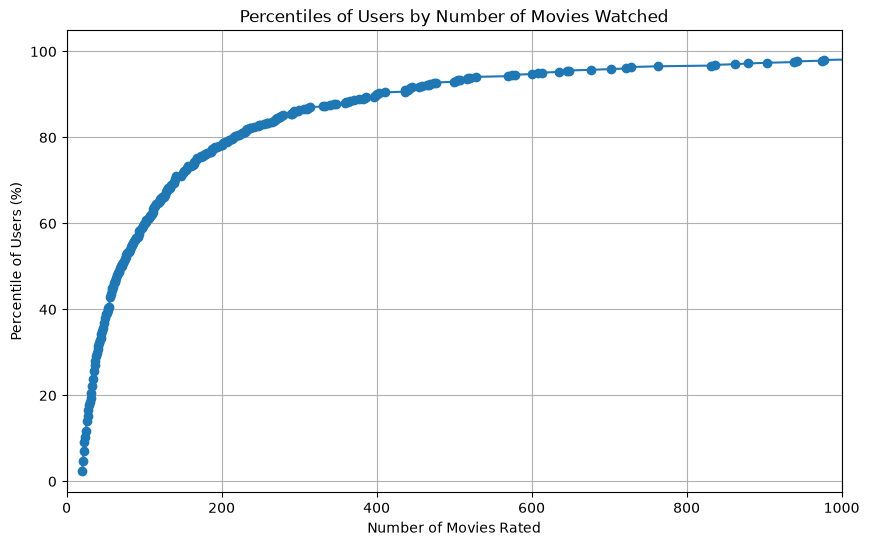

In [137]:
percentiles = movies_per_user.value_counts().sort_index().cumsum() / len(movies_per_user) * 100

# Plotting the percentiles
plt.figure(figsize=(10, 6))
plt.plot(percentiles.index, percentiles.values, marker='o')
plt.xlabel('Number of Movies Rated')
plt.ylabel('Percentile of Users (%)')
plt.title('Percentiles of Users by Number of Movies Watched')
plt.grid(True)
plt.xlim(0, 1000)
plt.show()

In [138]:
ratings_df.groupby(['userId','movieId']).size().max()

1

In [139]:
all_users_movie_combinations = pd.MultiIndex.from_product([ratings_df['userId'].unique(), movies_df['movieId'].unique()], names=['userId', 'movieId']).to_frame(index=False)

In [140]:
all_users_movie_combinations.head()

,userId,movieId
0,1,1
1,1,2
2,1,3
3,1,4
4,1,5


In [141]:
extended_ratings_df = pd.merge(all_users_movie_combinations, ratings_df, on=['userId', 'movieId'], how='left')
extended_ratings_df.fillna(0, inplace=True)

/var/folders/qm/jjr6jgjd4mg5n8mdb1n59gcw0000gn/T/ipykernel_54492/3467106652.py:2: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '0' has dtype incompatible with datetime64[ns], please explicitly cast to a compatible dtype first.
  extended_ratings_df.fillna(0, inplace=True)


## Łączenie tabelek

In [ ]:
merged_df = pd.merge(movies_df, extended_ratings_df, on='movieId', how='inner')

In [ ]:
merged_df = merged_df.merge(users_df, on='userId')

In [ ]:
ratings_df['rating'].value_counts()

In [ ]:
merged_df['watched'] = (merged_df['rating'] > 0) * 1

In [ ]:
merged_df ['watched'].mean()

In [ ]:
merged_df

In [ ]:
merged_df['watched'].mean()

## Trening modelu do klasyfikacji binarnej

In [ ]:
merged_df

In [ ]:
merged_df_drop = merged_df.drop(columns=['rating', 'timestamp', 'title', 'movieId']).fillna(0)

In [ ]:
train = merged_df_drop[merged_df_drop['userId'].isin(user_train['userId'])]
test = merged_df_drop[merged_df_drop['userId'].isin(user_test['userId'])]

In [ ]:
X_train = train.drop(columns = ['watched'])
y_train = train['watched']
X_test = test.drop(columns = ['watched'])
y_test = test['watched']

In [ ]:
X_train

In [ ]:
%%time

log_reg = LogisticRegression(max_iter = 1000)    
log_reg.fit(X_train, y_train)

In [ ]:
y_test_proba = log_reg.predict_proba(X_test)[:, 1]

In [ ]:
y_test_proba

In [ ]:
test_results_df

In [ ]:
usr_tab = test_results_df[test_results_df['userId'] == 3]


In [ ]:
usr_tab.sort_values('probability', ascending=False)

NameError: name 'usr_tab' is not defined

In [ ]:
usr_tab[usr_tab['watched'] == 1]